In [1]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch Version: 2.15.0+cpu
CUDA Available: False
Running on CPU


In [2]:
import pandas as pd
import numpy as np
import torch
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

print("Libraries imported successfully!")
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Libraries imported successfully!
Device: CPU


In [3]:
df = pd.read_csv("../data/raw/customer_feedback.csv")

df['review_text'] = (
    df['title'].fillna('') + ". " +
    df['content'].fillna('')
)

df = df.dropna(subset=['label', 'review_text'])

print("Dataset loaded:", df.shape)

df.head()

Dataset loaded: (10000, 4)


,label,title,content,review_text
0,0,Defected Product,I purchased this product because my cat prefer...,Defected Product. I purchased this product bec...
1,0,problem with product,The product I received came in time but was da...,problem with product. The product I received c...
2,0,can't handle power losses - active ports fry o...,I have just fried my second of this model. Whe...,can't handle power losses - active ports fry o...
3,0,"Looks great, poor performance",I bought this high end kettle thinking I would...,"Looks great, poor performance. I bought this h..."
4,1,perfect for loose teas,Looked a long time for this. Careful- it holds...,perfect for loose teas. Looked a long time for...


In [4]:
X = df['review_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [5]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

C:\Users\steve\Documents\Jini\PythonScripts\AIproject\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\steve\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 30522


In [6]:
sample_text = X_train.iloc[0]

tokens = tokenizer.tokenize(sample_text)

print("Original Review:")
print(sample_text)

print("\nTokens:")
print(tokens)

print("\nToken Count:", len(tokens))

Original Review:
the westing game is a good mystery. The Westing game is a mystery. It was a really interesting book for me.It starts out with the funeral of Mr. Sam Westing. His hairs are the people who recently got apartments in the Sunset Towers. But at the funeral the will says that Sam Westing was murdered, by one of them! And to inherit the money they have to find the killer. Soon everybody in the Sunset Towers is fighting for their life to find out who killed Sam Westing, if he is really dead that is.

Tokens:
['the', 'west', '##ing', 'game', 'is', 'a', 'good', 'mystery', '.', 'the', 'west', '##ing', 'game', 'is', 'a', 'mystery', '.', 'it', 'was', 'a', 'really', 'interesting', 'book', 'for', 'me', '.', 'it', 'starts', 'out', 'with', 'the', 'funeral', 'of', 'mr', '.', 'sam', 'west', '##ing', '.', 'his', 'hairs', 'are', 'the', 'people', 'who', 'recently', 'got', 'apartments', 'in', 'the', 'sunset', 'towers', '.', 'but', 'at', 'the', 'funeral', 'the', 'will', 'says', 'that', 'sam',

In [7]:
encoded = tokenizer(
    sample_text,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

print("Input IDs:")
print(encoded['input_ids'])

print("\nAttention Mask:")
print(encoded['attention_mask'])

print("\nInput Shape:")
print(encoded['input_ids'].shape)

Input IDs:
tensor([[  101,  1996,  2225,  2075,  2208,  2003,  1037,  2204,  6547,  1012,
          1996,  2225,  2075,  2208,  2003,  1037,  6547,  1012,  2009,  2001,
          1037,  2428,  5875,  2338,  2005,  2033,  1012,  2009,  4627,  2041,
          2007,  1996,  6715,  1997,  2720,  1012,  3520,  2225,  2075,  1012,
          2010, 13606,  2024,  1996,  2111,  2040,  3728,  2288,  9620,  1999,
          1996, 10434,  7626,  1012,  2021,  2012,  1996,  6715,  1996,  2097,
          2758,  2008,  3520,  2225,  2075,  2001,  7129,  1010,  2011,  2028,
          1997,  2068,   999,  1998,  2000, 22490,  1996,  2769,  2027,  2031,
          2000,  2424,  1996,  6359,  1012,  2574,  7955,  1999,  1996, 10434,
          7626,  2003,  3554,  2005,  2037,  2166,  2000,  2424,  2041,  2040,
          2730,  3520,  2225,  2075,  1010,  2065,  2002,  2003,  2428,  2757,
          2008,  2003,  1012,   102,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     

In [8]:
decoded_text = tokenizer.decode(
    encoded['input_ids'][0],
    skip_special_tokens=True
)

print("Original Text:")
print(sample_text)

print("\nDecoded Text:")
print(decoded_text)

Original Text:
the westing game is a good mystery. The Westing game is a mystery. It was a really interesting book for me.It starts out with the funeral of Mr. Sam Westing. His hairs are the people who recently got apartments in the Sunset Towers. But at the funeral the will says that Sam Westing was murdered, by one of them! And to inherit the money they have to find the killer. Soon everybody in the Sunset Towers is fighting for their life to find out who killed Sam Westing, if he is really dead that is.

Decoded Text:
the westing game is a good mystery. the westing game is a mystery. it was a really interesting book for me. it starts out with the funeral of mr. sam westing. his hairs are the people who recently got apartments in the sunset towers. but at the funeral the will says that sam westing was murdered, by one of them! and to inherit the money they have to find the killer. soon everybody in the sunset towers is fighting for their life to find out who killed sam westing, if he

In [9]:
from datasets import Dataset

train_dataset = Dataset.from_dict({
    "text": X_train.tolist(),
    "label": y_train.tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_test.tolist(),
    "label": y_test.tolist()
})

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 8000
Testing dataset: 2000


In [10]:
def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )


train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True
)

test_tokenized = test_dataset.map(
    tokenize_function,
    batched=True
)

print("Training tokenization completed!")
print("Testing tokenization completed!")

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Training tokenization completed!
Testing tokenization completed!


In [11]:
print(train_tokenized)

print("\nFirst tokenized review:")

print(train_tokenized[0])

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 8000
})

First tokenized review:
{'text': 'the westing game is a good mystery. The Westing game is a mystery. It was a really interesting book for me.It starts out with the funeral of Mr. Sam Westing. His hairs are the people who recently got apartments in the Sunset Towers. But at the funeral the will says that Sam Westing was murdered, by one of them! And to inherit the money they have to find the killer. Soon everybody in the Sunset Towers is fighting for their life to find out who killed Sam Westing, if he is really dead that is.', 'label': 1, 'input_ids': [101, 1996, 2225, 2075, 2208, 2003, 1037, 2204, 6547, 1012, 1996, 2225, 2075, 2208, 2003, 1037, 6547, 1012, 2009, 2001, 1037, 2428, 5875, 2338, 2005, 2033, 1012, 2009, 4627, 2041, 2007, 1996, 6715, 1997, 2720, 1012, 3520, 2225, 2075, 1012, 2010, 13606, 2024, 1996, 2111, 2040, 3728, 2288, 9620, 1999, 1996, 10434, 7626, 1012, 2

In [12]:
# Remove unnecessary columns
train_tokenized = train_tokenized.remove_columns(
    ["text", "token_type_ids"]
)

test_tokenized = test_tokenized.remove_columns(
    ["text", "token_type_ids"]
)

print("Training columns:", train_tokenized.column_names)
print("Testing columns:", test_tokenized.column_names)

Training columns: ['label', 'input_ids', 'attention_mask']
Testing columns: ['label', 'input_ids', 'attention_mask']


In [13]:
MODEL_NAME = "distilbert-base-uncased"

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "Negative",
        1: "Positive"
    },
    label2id={
        "Negative": 0,
        "Positive": 1
    }
)

print("DistilBERT model loaded successfully!")

C:\Users\steve\Documents\Jini\PythonScripts\AIproject\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\steve\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [14]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Data collator prepared successfully!")

Data collator prepared successfully!


In [18]:
from transformers import (
    Trainer,
    TrainingArguments
)

import time          
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average='binary',
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics configured successfully!")

Evaluation metrics configured successfully!


In [19]:
training_args = TrainingArguments(

    output_dir="./results/distilbert_sentiment",

    num_train_epochs=1,

    per_device_train_batch_size=4,

    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    weight_decay=0.01,

    eval_strategy="epoch",

    save_strategy="no",

    logging_steps=100,

    report_to="none",

    use_cpu=True
)

print("Training configuration completed!")

Training configuration completed!


In [20]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_tokenized,

    eval_dataset=test_tokenized,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer initialized successfully!")

Trainer initialized successfully!


In [21]:
start_time = time.time()

train_result = trainer.train()

end_time = time.time()

training_time = (end_time - start_time) / 60

print("Training completed!")
print("Training time:", round(training_time, 2), "minutes")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.304289,0.286265,0.932500,0.932866,0.931932,0.932399


Training completed!
Training time: 111.48 minutes


In [22]:
# Evaluate the trained model

evaluation_results = trainer.evaluate()

print("\nDistilBERT Evaluation Results")

for metric, value in evaluation_results.items():

    print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.304289,0.286265,1,0.932500,0.932866,0.931932,0.932399



DistilBERT Evaluation Results
eval_loss: 0.2863
eval_accuracy: 0.9325
eval_precision: 0.9329
eval_recall: 0.9319
eval_f1: 0.9324


In [23]:
from sklearn.metrics import classification_report

predictions_output = trainer.predict(test_tokenized)

y_pred = np.argmax(
    predictions_output.predictions,
    axis=1
)

y_true = predictions_output.label_ids

print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.93      0.93      0.93      1001
    Positive       0.93      0.93      0.93       999

    accuracy                           0.93      2000
   macro avg       0.93      0.93      0.93      2000
weighted avg       0.93      0.93      0.93      2000



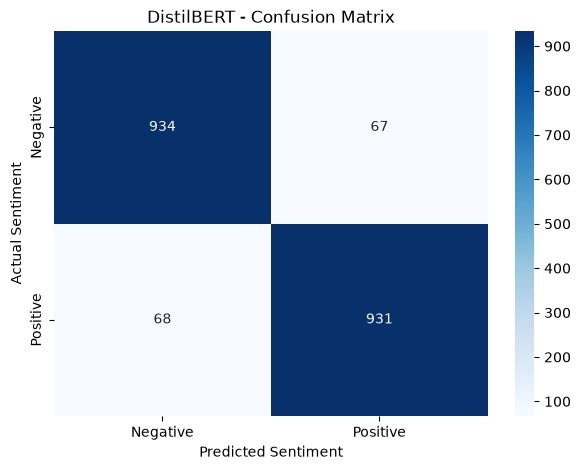

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [26]:
for name, obj in globals().copy().items():
    if hasattr(obj, "predict"):
        module = type(obj).__module__

        if "sklearn" in module:
            print("Variable name:", name)
            print("Model type:", type(obj).__name__)
            print("-" * 40)

In [27]:
import os

# Create directory for DistilBERT
bert_model_dir = "../models/distilbert_sentiment"
os.makedirs(bert_model_dir, exist_ok=True)

# Save trained model
model.save_pretrained(bert_model_dir)

# Save tokenizer
tokenizer.save_pretrained(bert_model_dir)

print("DistilBERT model saved successfully!")
print("Tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved successfully!
Tokenizer saved successfully!
